In [1]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import yaml
from sbi.utils.sbiutils import gradient_ascent

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.posteriors import DirectPosterior

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from functools import partial
import sys
sys.path.append('../src')

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_spline

In [3]:
data_cfg = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/data/base/config.yaml"

In [4]:
prior = generate_posterior_prior_from_config(data_cfg, device="cuda")

In [5]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [6]:
fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg)

In [7]:
true_params = torch.tensor([ 0.100, -1.5938, -1.7873, -1.5556,  1.1016, -2.1840,  8.0000, 8.000, 0.0500,  0.0500,  0.7500,  0.7500,  0.9000,  0.9000,  0.1000,  0.1000], dtype=torch.float64)

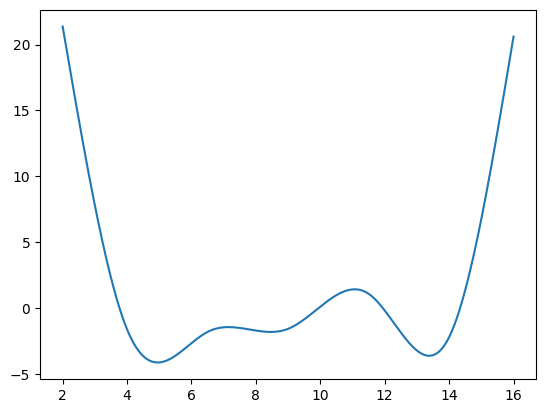

In [8]:
x, y = eval_spline(
    params=true_params,
    x_eval=np.linspace(2, 16, 1000),
    N_knots=5,
    x_min=4,
    x_max=14,
    boundary_condition='bound',
    max_G0=30,
    spline_type="cubic"
)
plt.plot(x, y)

In [9]:
observation = torch.stack([fret_simulator(true_params) for _ in range(1)])

Text(0.5, 0, 'Time')

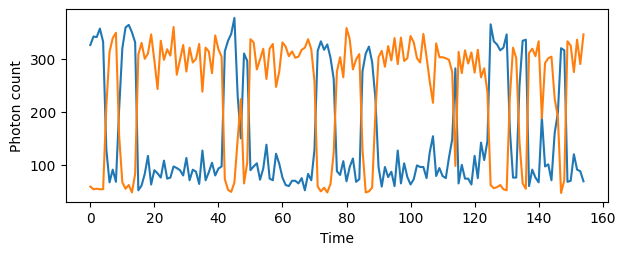

In [10]:
idx = 0
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[idx, :,0].numpy(), n_bins=155), label="Donor")
plt.plot(bin_along_time(observation[idx, :,1].numpy(), n_bins=155), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")


In [ ]:
with open("/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/density_estimator/2026-03-03/18-22-53/density_estimator.pkl", "rb") as f:
    density_estimator = pickle.load(f)
density_estimator = density_estimator.cuda()

In [ ]:
posterior = DirectPosterior(density_estimator, prior=prior)

In [ ]:
samples = density_estimator.sample((10000,), condition=observation.cuda()).cpu().detach()
samples = samples.reshape(-1, 6) 

In [ ]:
_ = analysis.pairplot(
    samples,
    figsize=(7,7),
    points=true_params, 
    points_offdiag={'markersize': 6},
    points_colors='r', 
)

In [ ]:
samples[:, 1:] = samples[:, 1:] - samples[:, 1:].mean(dim=1, keepdim=True)